# 04. 방식별 튜닝(E05)

기본 학습(E01~E04)을 보고 방식마다 **한 요인만** 바꿨습니다. 계획과 채택 기준은 실행 전에 `experiments/E05/PLAN.md`에 적었습니다.

| ID | 전략 | 바꾼 것 | 이유 |
|---|---|---|---|
| E05a | Scratch | 증강(좌우 뒤집기 + 이동 ±5%·확대축소 0.9~1.1) | 과적합 |
| E05b | Feature Extraction | `fc` 학습률 1e-3 → 1e-2 | 과소적합 |
| E05c | Partial FT | 증강 | Train을 거의 외움 |
| E05d | Full FT | 증강 | Train을 다 외움 |

**채택 기준(미리 정함)**: Val Macro F1이 기본보다 **+0.02 이상**이면 개선, ±0.02 미만이면 차이 없음, −0.02 이하면 악화.

**왜 증강이 과적합에 듣는가**: 같은 사진을 매 epoch 조금씩 다르게(뒤집고, 옮기고, 키우고) 보여 주면, 모델이 사진 한 장 한 장을 외우기 어려워집니다. 대신 여러 변형에 공통인 특징(자세, 기구)을 배우도록 유도합니다. 반대로 FE처럼 *덜 배운* 모델에는 증강이 문제를 더 어렵게 만들 뿐이라, FE는 학습률을 바꿨습니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 180)
NAMES = class_names()
PAIRS = [("scratch", "E01", "E05a", "증강"), ("fe", "E02", "E05b", "lr 1e-2"),
         ("partial", "E03", "E05c", "증강"), ("full", "E04", "E05d", "증강")]
LABEL = {"scratch": "Scratch", "fe": "Feature Extraction", "partial": "Partial FT", "full": "Full FT"}

def load(rid, s):
    d = ROOT / "experiments" / rid / s
    return (pd.read_csv(d / "history.csv"), json.loads((d / "summary.json").read_text(encoding="utf-8")))

R = {}
for s, base, tuned, _ in PAIRS:
    R[base] = load(base, s); R[tuned] = load(tuned, s)

font: Malgun Gothic


## 1. 기본 대비 결과와 판정

In [2]:
def verdict(d):
    return "개선(채택 후보)" if d >= 0.02 else ("악화" if d <= -0.02 else "차이 없음")
rows = []
for s, base, tuned, what in PAIRS:
    (hb, sb), (ht, st) = R[base], R[tuned]
    tb = ht[ht.epoch == st["best_epoch"]].iloc[0]; bb = hb[hb.epoch == sb["best_epoch"]].iloc[0]
    d = st["val"]["macro_f1"] - sb["val"]["macro_f1"]
    rows.append({"전략": LABEL[s], "바꾼 것": what, "기본 F1": round(sb["val"]["macro_f1"], 4), "튜닝 F1": round(st["val"]["macro_f1"], 4),
                 "차이": round(d, 4), "판정": verdict(d),
                 "기본 Train−Val Acc": round(bb.train_acc - sb["val"]["accuracy"], 3), "튜닝 Train−Val Acc": round(tb.train_acc - st["val"]["accuracy"], 3),
                 "최고 epoch(기본→튜닝)": f"{sb['best_epoch']}→{st['best_epoch']}",
                 "시간(분, 기본→튜닝)": f"{sb['total_time_s']/60:.1f}→{st['total_time_s']/60:.1f}"})
res = pd.DataFrame(rows); res

,전략,바꾼 것,기본 F1,튜닝 F1,차이,판정,기본 Train−Val Acc,튜닝 Train−Val Acc,최고 epoch(기본→튜닝),"시간(분, 기본→튜닝)"
0,Scratch,증강,0.7928,0.7130,-0.0798,악화,0.154,0.072,9→8,3.0→2.8
1,Feature Extraction,lr 1e-2,0.7678,0.7351,-0.0328,악화,0.089,0.087,13→4,2.7→1.5
2,Partial FT,증강,0.8311,0.8144,-0.0166,차이 없음,0.143,0.067,15→5,3.1→1.8
3,Full FT,증강,0.8581,0.8698,0.0117,차이 없음,0.132,0.084,16→8,4.4→2.8


## 2. 학습 곡선: 기본(점선) vs 튜닝(실선)

위: Val Macro F1. 아래: Train Accuracy(옅은 색)와 Val Accuracy(진한 색). 증강이 과적합을 줄였다면 Train과 Val의 간격이 좁아집니다.

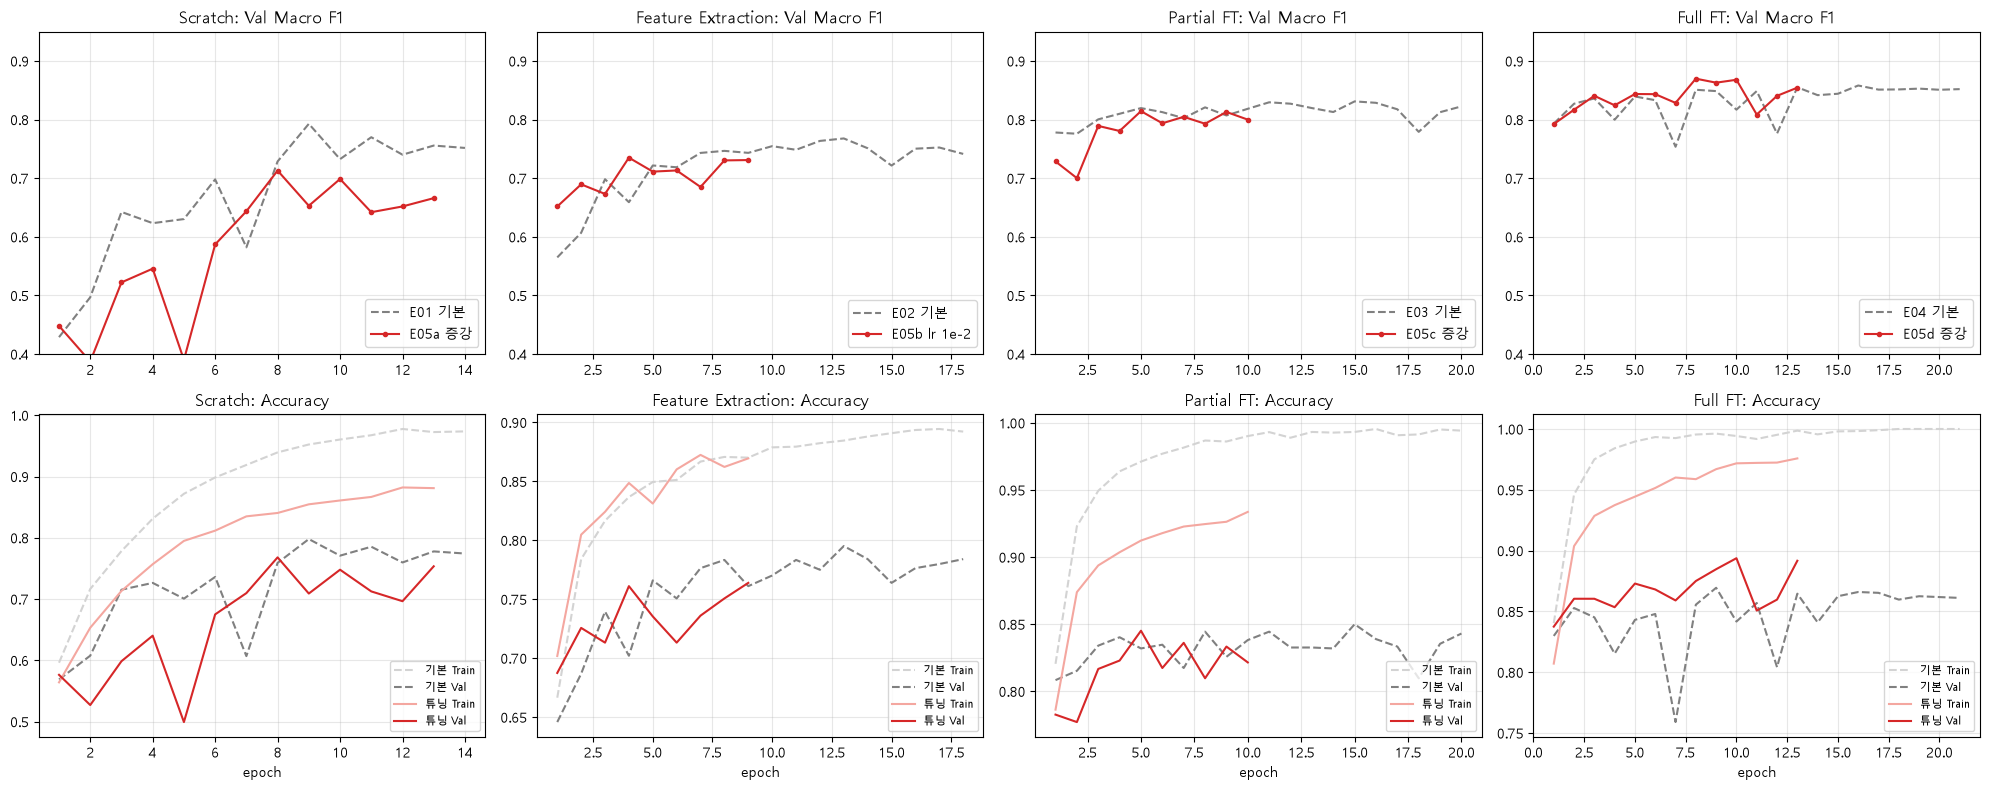

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=False)
for k, (s, base, tuned, what) in enumerate(PAIRS):
    (hb, sb), (ht, st) = R[base], R[tuned]
    ax = axes[0, k]
    ax.plot(hb.epoch, hb.val_macro_f1, "--", color="gray", label=f"{base} 기본")
    ax.plot(ht.epoch, ht.val_macro_f1, "-", color="C3", label=f"{tuned} {what}", marker=".")
    ax.set_title(f"{LABEL[s]}: Val Macro F1"); ax.legend(loc="lower right"); ax.grid(alpha=.3); ax.set_ylim(0.4, 0.95)
    ax = axes[1, k]
    ax.plot(hb.epoch, hb.train_acc, "--", color="lightgray", label="기본 Train"); ax.plot(hb.epoch, hb.val_acc, "--", color="gray", label="기본 Val")
    ax.plot(ht.epoch, ht.train_acc, "-", color="#F4A7A0", label="튜닝 Train"); ax.plot(ht.epoch, ht.val_acc, "-", color="C3", label="튜닝 Val")
    ax.set_title(f"{LABEL[s]}: Accuracy"); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "e05_curves.png", dpi=100); plt.show()

## 3. 클래스별 F1 변화(튜닝 − 기본)

초록은 좋아진 클래스, 빨강은 나빠진 클래스입니다. 바벨·덤벨 묶음(2·7·8·9)이 움직였는지가 핵심입니다. 클래스마다 Val은 한 사람(64~160장)이라 작은 변화는 몇 클립의 차이일 수 있습니다.

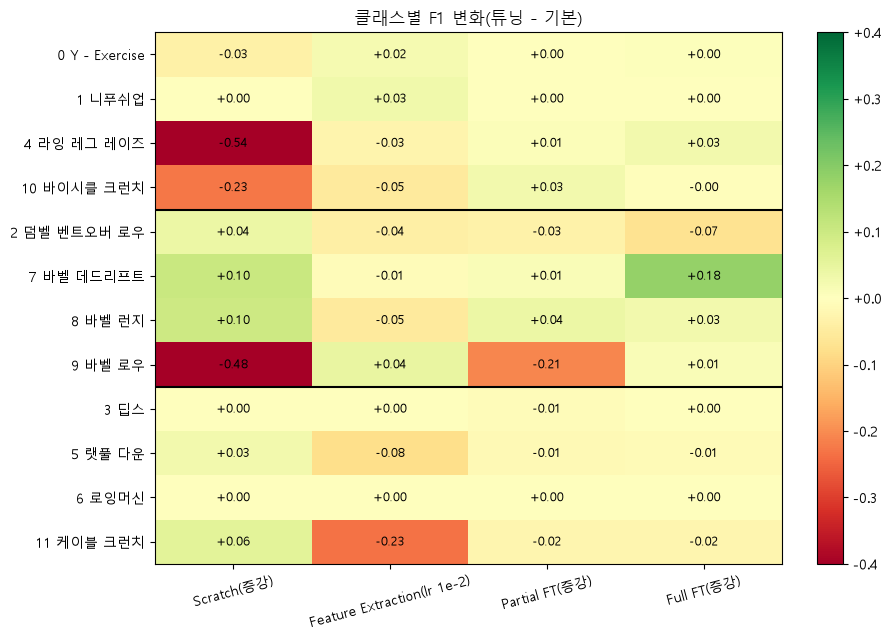

Recall이 0.15 넘게 떨어진 클래스(채택 기준 확인용): {'Scratch': {'라잉 레그 레이즈': -0.695, '바벨 로우': -0.5}, 'Feature Extraction': {'바벨 런지': -0.231, '케이블 크런치': -0.375}, 'Partial FT': {'바벨 로우': -0.172}, 'Full FT': {}}


In [4]:
order = [c for g in GROUPS.values() for c in g]
delta = pd.DataFrame({f"{LABEL[s]}({what})": [R[tuned][1]["val"]["per_class"]["f1"][NAMES[c]] - R[base][1]["val"]["per_class"]["f1"][NAMES[c]] for c in order]
                      for s, base, tuned, what in PAIRS}, index=[f"{c} {NAMES[c]}" for c in order])
fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(delta.values, cmap="RdYlGn", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(delta.columns, rotation=15); ax.set_yticks(range(12)); ax.set_yticklabels(delta.index)
for i in range(12):
    for j in range(4):
        ax.text(j, i, f"{delta.values[i, j]:+.2f}", ha="center", va="center", fontsize=9)
for y in (3.5, 7.5): ax.axhline(y, color="k", lw=1.5)
from matplotlib.ticker import FuncFormatter
cb = plt.colorbar(im, ax=ax, fraction=0.04); cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.1f}"))
ax.set_title("클래스별 F1 변화(튜닝 - 기본)")
plt.tight_layout(); plt.savefig(FIGURES / "e05_per_class_delta.png", dpi=110); plt.show()
recall_drop = {f"{LABEL[s]}": {NAMES[c]: round(R[tuned][1]["val"]["per_class"]["recall"][NAMES[c]] - R[base][1]["val"]["per_class"]["recall"][NAMES[c]], 3)
               for c in order if R[tuned][1]["val"]["per_class"]["recall"][NAMES[c]] - R[base][1]["val"]["per_class"]["recall"][NAMES[c]] < -0.15}
               for s, base, tuned, what in PAIRS}
print("Recall이 0.15 넘게 떨어진 클래스(채택 기준 확인용):", recall_drop)

## 4. 바벨·덤벨 묶음 혼동(정답→예측 장수)

In [5]:
sub = [2, 7, 8, 9]
rows = []
for s, base, tuned, what in PAIRS:
    for rid in (base, tuned):
        cm = np.array(R[rid][1]["val"]["confusion_matrix"])
        rows.append({"전략": LABEL[s], "실행": rid, "7→9": cm[7, 9], "9→7": cm[9, 7], "2→7": cm[2, 7], "7→2": cm[7, 2], "9→2": cm[9, 2],
                     "바벨 로우 Recall": round(cm[9, 9] / cm[9].sum(), 3), "데드리프트 Recall": round(cm[7, 7] / cm[7].sum(), 3),
                     "덤벨 로우 Recall": round(cm[2, 2] / cm[2].sum(), 3)})
pd.DataFrame(rows)

,전략,실행,7→9,9→7,2→7,7→2,9→2,바벨 로우 Recall,데드리프트 Recall,덤벨 로우 Recall
0,Scratch,E01,30,17,45,53,7,0.500,0.444,0.512
1,Scratch,E05a,0,15,35,70,39,0.000,0.544,0.619
2,Feature Extraction,E02,10,17,28,44,25,0.094,0.569,0.644
3,Feature Extraction,E05b,15,30,53,22,21,0.156,0.738,0.531
4,Partial FT,E03,14,26,57,16,18,0.203,0.788,0.531
5,Partial FT,E05c,9,28,62,23,33,0.031,0.800,0.575
6,Full FT,E04,82,13,3,14,11,0.531,0.400,0.794
7,Full FT,E05d,62,6,5,3,18,0.578,0.594,0.662


## 5. 해석

### 5.1 미리 정한 기준으로는 채택할 튜닝이 없습니다

| 실행 | 기본 → 튜닝 | 차이 | 판정 |
|---|---|---|---|
| E05a Scratch + 증강 | 0.793 → 0.713 | −0.080 | 악화 |
| E05b FE lr 1e-2 | 0.768 → 0.735 | −0.033 | 악화 |
| E05c Partial + 증강 | 0.831 → 0.814 | −0.017 | 차이 없음 |
| E05d Full + 증강 | 0.858 → 0.870 | +0.012 | 차이 없음 |

규칙대로 네 방식 모두 **기본 조건을 유지**합니다. Full + 증강의 0.870은 지금까지 가장 높은 값입니다. 그러나 +0.012는 E00에서 본 잡음 범위(0.01~0.04) 안이라 "증강이 좋다"고 말할 근거가 되지 않습니다. 실패한 튜닝도 결과 표에 그대로 남깁니다.

### 5.2 증강은 과적합 간격을 줄였지만, 조기 종료가 너무 빨리 걸렸습니다

| 전략 | Train−Val Acc(기본 → 증강) | 최고 epoch(기본 → 증강) | 멈춘 epoch |
|---|---|---|---|
| Scratch | 0.154 → 0.072 | 9 → 8 | 14 → 13 |
| Partial FT | 0.143 → 0.067 | 15 → 5 | 20 → 10 |
| Full FT | 0.132 → 0.084 | 16 → 8 | 21 → 13 |

- 세 방식 모두 Train과 Val의 간격이 절반 가까이 줄었습니다. **증강은 의도대로 "외우기"를 막았습니다.**
- 그런데 증강을 켜면 매 epoch 보는 사진이 달라집니다. 그래서 학습이 느려지고 Val 점수가 더 출렁입니다. Scratch + 증강은 5 epoch에 F1 0.39로 떨어졌다가 회복하는 등 크게 흔들렸습니다. 13 epoch에 멈출 때 Train Accuracy가 0.88, Train Loss가 0.29로 아직 내려가는 중이었습니다. **patience 5가 증강 학습에는 짧아서, 다 배우기 전에 멈췄을 가능성**이 있습니다(가설, 아래 2차 튜닝으로 확인 가능).
- Full + 증강은 Val Loss도 낮아졌습니다(최고 시점 0.33, 기본 0.49). 틀린 예측에 대한 과신이 줄었다는 뜻입니다.

### 5.3 FE의 학습률을 올려도 나아지지 않았습니다

- lr 1e-2에서는 Train Loss가 5·8 epoch에 튀며 불안정해졌고, 4 epoch에서 최고점을 찍은 뒤 멈췄습니다. Train Accuracy는 여전히 0.87 근처였습니다.
- 학습 속도가 문제였다면 lr을 올렸을 때 Train Accuracy가 올라갔어야 합니다. 그렇지 않았으므로 **FE의 한계는 학습률이 아니라 고정된 ImageNet 특징 자체**라는 해석(03 노트북 5.1)이 더 힘을 얻습니다.

### 5.4 데드리프트·바벨 로우 혼동은 증강으로 풀리지 않았습니다

- Full + 증강: 데드리프트 Recall 0.40 → 0.59, 바벨 로우 0.53 → 0.58로 올랐습니다. 대신 덤벨 로우는 0.79 → 0.66으로 내렸습니다. 혼동이 사라진 것이 아니라 **자리를 옮겼습니다**(여전히 데드리프트 62장을 로우로 예측).
- Scratch + 증강과 Partial + 증강은 바벨 로우를 거의 못 맞혔습니다(Recall 0.00, 0.03).
- 좌우 뒤집기와 약한 이동·확대는 "같은 자세를 조금 다르게 보는" 변형입니다. 반면 7↔9는 **같은 순간의 자세가 거의 같다**는 문제입니다. 그래서 이 증강으로는 풀기 어려운 혼동입니다. 사람 영역을 키우는 입력(가설 H-b)이나 오류 분석(E06)으로 원인을 먼저 좁히는 편이 맞습니다.

### 5.5 2차 튜닝 후보(D-014: 방식당 최대 1회 더)

| 후보 | 바꾸는 것(E05 대비 한 요인) | 확인하려는 것 |
|---|---|---|
| Full + 증강 + patience 10 | patience 5 → 10 | 증강 학습이 일찍 멈춘 탓인지 |
| Scratch + 증강 + patience 10 | patience 5 → 10 | 같은 질문. Scratch는 Train이 아직 덜 배운 상태에서 멈췄음 |
| FE | 2차 튜닝 생략 | 구조상 한계로 보임. 공식 최소 1회는 충족 |

주의: patience를 늘리면 Val을 더 많이 보고 그중 최고를 고르게 됩니다. 운 좋은 최고점을 고를 가능성도 커집니다. 그래서 2차 튜닝도 +0.02 기준을 그대로 씁니다.

## 6. 2차 튜닝: 증강 + patience 10(E05e·E05f)

1차에서 증강을 켜면 조기 종료가 일찍 걸렸습니다. **patience만** 5 → 10으로 늘려(증강 조건 대비 한 요인) "다 배우기 전에 멈췄는가"를 확인합니다. 판정은 기본(E01·E04) 대비, 기준은 같습니다(+0.02). 계획은 실행 전에 `experiments/E05/PLAN.md` 2차 절에 적었습니다.

In [6]:
P2 = [("scratch", "E01", "E05a", "E05e"), ("full", "E04", "E05d", "E05f")]
for s, base, r1, r2 in P2:
    R[r2] = load(r2, s)
rows = []
for s, base, r1, r2 in P2:
    for rid, cond in ((base, "기본"), (r1, "증강, patience 5"), (r2, "증강, patience 10")):
        h, sm = R[rid]
        b = h[h.epoch == sm["best_epoch"]].iloc[0]
        rows.append({"전략": LABEL[s], "실행": rid, "조건": cond, "Val Macro F1": round(sm["val"]["macro_f1"], 4),
                     "기본 대비": round(sm["val"]["macro_f1"] - R[base][1]["val"]["macro_f1"], 4),
                     "판정": "" if rid == base else verdict(sm["val"]["macro_f1"] - R[base][1]["val"]["macro_f1"]),
                     "최고/멈춘 epoch": f"{sm['best_epoch']}/{sm['epochs_run']}", "최고 시점 Train Acc": round(b.train_acc, 3),
                     "Train−Val Acc": round(b.train_acc - sm["val"]["accuracy"], 3), "시간(분)": round(sm["total_time_s"] / 60, 1)})
pd.DataFrame(rows)

,전략,실행,조건,Val Macro F1,기본 대비,판정,최고/멈춘 epoch,최고 시점 Train Acc,Train−Val Acc,시간(분)
0,Scratch,E01,기본,0.7928,0.0000,,9/14,0.952,0.154,3.0
1,Scratch,E05a,"증강, patience 5",0.7130,-0.0798,악화,8/13,0.840,0.072,2.8
2,Scratch,E05e,"증강, patience 10",0.7785,-0.0143,차이 없음,26/36,0.937,0.107,7.2
3,Full FT,E04,기본,0.8581,0.0000,,16/21,0.998,0.132,4.4
4,Full FT,E05d,"증강, patience 5",0.8698,0.0117,차이 없음,8/13,0.959,0.084,2.8
5,Full FT,E05f,"증강, patience 10",0.8698,0.0117,차이 없음,8/18,0.959,0.084,3.8


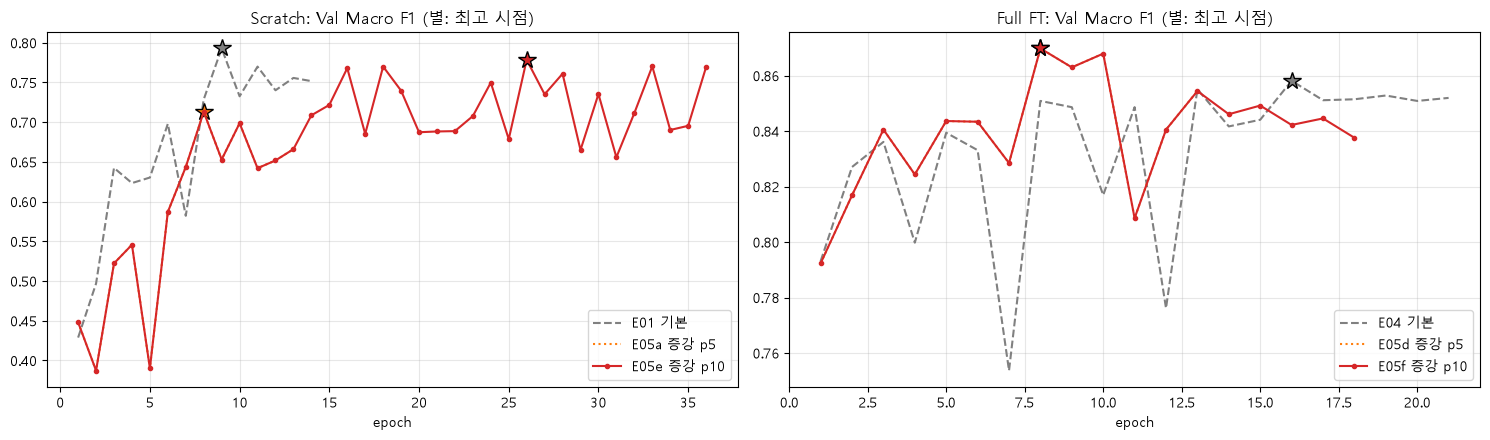

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (s, base, r1, r2) in zip(axes, P2):
    for rid, sty, col, lab in ((base, "--", "gray", "기본"), (r1, ":", "C1", "증강 p5"), (r2, "-", "C3", "증강 p10")):
        h, sm = R[rid]
        ax.plot(h.epoch, h.val_macro_f1, sty, color=col, label=f"{rid} {lab}", marker="." if rid == r2 else None)
        ax.plot(sm["best_epoch"], sm["val"]["macro_f1"], "*", ms=13, color=col, mec="k")
    ax.set_title(f"{LABEL[s]}: Val Macro F1 (별: 최고 시점)"); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "e05_round2_curves.png", dpi=100); plt.show()

In [8]:
rows = []
for s, base, r1, r2 in P2:
    for rid in (base, r1, r2):
        sm = R[rid][1]; pc = sm["val"]["per_class"]["recall"]
        rows.append({"전략": LABEL[s], "실행": rid, **{f"{c} {NAMES[c]}": round(pc[NAMES[c]], 2) for c in (2, 7, 8, 9, 4, 10)}})
print("클래스별 Recall(바벨·덤벨 묶음과 맨몸 일부)")
pd.DataFrame(rows)

클래스별 Recall(바벨·덤벨 묶음과 맨몸 일부)


,전략,실행,2 덤벨 벤트오버 로우,7 바벨 데드리프트,8 바벨 런지,9 바벨 로우,4 라잉 레그 레이즈,10 바이시클 크런치
0,Scratch,E01,0.51,0.44,0.75,0.50,0.91,0.64
1,Scratch,E05a,0.62,0.54,0.91,0.00,0.21,0.83
2,Scratch,E05e,0.81,0.63,0.93,0.00,0.57,0.83
3,Full FT,E04,0.79,0.40,0.95,0.53,0.85,0.97
4,Full FT,E05d,0.66,0.59,0.95,0.58,0.90,0.98
5,Full FT,E05f,0.66,0.59,0.95,0.58,0.90,0.98


### 6.1 해석

| 실행 | 조건 | Val Macro F1 | 기본 대비 | 판정 |
|---|---|---|---|---|
| E05e | Scratch, 증강 + patience 10 | 0.7785 | −0.014 | 차이 없음 |
| E05f | Full FT, 증강 + patience 10 | 0.8698 | +0.012 | 차이 없음 |

- **Scratch는 정말 "일찍 멈춘" 것이었습니다.** patience만 늘렸더니 0.713 → 0.779(+0.066)로 올랐습니다. 최고점은 26 epoch이었습니다. 1차(patience 5)는 13 epoch에 멈췄으니 절반밖에 학습하지 못한 셈입니다. 다만 기본(증강 없음, 0.793)을 넘지는 못했습니다.
- **같은 seed·결정적 모드라서 1~13 epoch가 1차와 똑같이 재현되었습니다**(F1이 소수 넷째 자리까지 같음). 두 실행의 차이는 정말로 "14 epoch부터 더 학습했는가"뿐입니다. 결정적 모드로 바꾼 덕분에 이런 깨끗한 비교가 가능했습니다.
- **Scratch + 증강의 Val은 끝까지 크게 출렁였습니다**(26~36 epoch에도 0.66~0.78). 이렇게 출렁이는 곡선에서 최고점 하나를 고르면 운이 크게 섞입니다. patience를 늘릴수록 더 많은 봉우리 중에서 고르게 되므로, 이 0.779도 낙관적인 값일 수 있습니다.
- **Scratch + 증강은 바벨 로우를 한 장도 맞히지 못했습니다**(Recall 0.00, patience 5·10 모두). 대신 덤벨 로우(0.51 → 0.81)와 데드리프트(0.44 → 0.63)는 기본보다 올랐습니다. 가장 적은 클래스(Train 312장)를 옆 클래스로 흡수해 버린 모양입니다. 한 클래스가 0점이면 Macro F1에서 그것만으로 최대 약 0.04(12개 중 하나의 F1 몫)가 빠집니다. 그래서 기본과의 −0.014 차이도 "전체가 나빠졌다"기보다 "바벨 로우를 잃고 나머지는 비슷하거나 나아졌다"로 읽는 것이 정확합니다. 클래스 불균형 대응(가중치 등)은 오류 분석(E06) 뒤 개선 실험 후보입니다.
- **Full은 patience를 늘려도 그대로였습니다**(8 epoch 최고, 이후 10 epoch 동안 0.84~0.87 사이에서 오르지 않음). Full은 사전학습 덕분에 빨리 수렴해서, 1차에서 일찍 멈춘 것이 손해가 아니었습니다.

### 6.2 튜닝 단계 결론

- 방식별 튜닝을 1~2회씩 마쳤습니다(Scratch 2회, FE 1회, Partial 1회, Full 2회. 공식 최소 1회 충족). 미리 정한 기준(+0.02)을 넘은 것은 없어서 **네 방식 모두 기본 조건을 유지**합니다.
- 기본 학습의 순서(Full > Partial > Scratch > FE)는 튜닝 뒤에도 바뀌지 않았습니다.
- 배운 점
  1. 튜닝 요인은 서로 얽힙니다. 증강은 학습을 느리게 해서, 조기 종료 설정(patience)과 함께 봐야 합니다.
  2. 같은 seed·결정적 모드는 "한 요인만 바꾼 비교"를 깨끗하게 만들어 줍니다.
  3. Val이 운동당 한 사람이라 곡선이 출렁입니다. 0.01~0.02 차이로는 결론을 내리지 않습니다.
- **최종 선정(E08) 전에 정할 것**: 지금 가장 높은 Val 값은 Full + 증강(0.870)이고, 기본 Full은 0.858입니다. 튜닝 채택 기준으로는 "차이 없음"입니다. 최종 선정 규칙(D-015)은 "Val Macro F1 최고, 0.01 미만 차이는 짧은 쪽"입니다. 이 둘이 어긋나므로 선정 전에 규칙을 맞춰야 합니다. 차이가 잡음 범위라, 두 후보를 seed 몇 개로 반복해 평균을 비교하는 방법(선택 항목 "여러 seed")을 제안합니다.